# CSC2107: Design & Analysis of Algorithms
## Assignment 5.1 — Naive vs. Memoized Fibonacci

**Due Date:** October 22, 2026

### Objective

The purpose of this assignment is to compare two algorithms for computing Fibonacci numbers:

1. **Algorithm A — Naive Recursive Fibonacci**
2. **Algorithm B — Recursive Fibonacci with Memoization**

Both algorithms compute the Fibonacci sequence defined by:

$$
F(0)=0
$$

$$
F(1)=1
$$

and for $n \geq 2$:

$$
F(n)=F(n-1)+F(n-2)
$$

The two algorithms produce the same Fibonacci values, but they differ greatly in efficiency.

This notebook implements both algorithms in Python, counts the number of function calls, measures execution time, plots the experimental results, and analyses their time and space complexities.

## Required Python Libraries

The following libraries are used in this notebook:

- `time` is used to measure execution time using `time.perf_counter()`.
- `sys` is used to inspect and modify Python's recursion limit.
- `math` is used for mathematical calculations.
- `matplotlib.pyplot` is used to create graphs for the experimental results.

In [16]:
import time
import sys
import math
import matplotlib.pyplot as plt

# Part 1: Implementation

In this section, both Fibonacci algorithms are implemented.

A global counter is added to each function so that the number of function calls can be recorded.

This will allow us to compare not only execution time but also the amount of recursive work performed by each algorithm.

## Algorithm A: Naive Recursive Fibonacci

The naive Fibonacci algorithm directly follows the mathematical definition:

$$
F(n)=F(n-1)+F(n-2)
$$

For every value greater than 1, the function recursively calculates both $F(n-1)$ and $F(n-2)$.

The problem with this method is that the same Fibonacci values are calculated many times.

For example, while calculating $F(5)$, the value $F(3)$ is calculated more than once.

A global variable called `calls_a` is used to count every invocation of the function.

In [17]:
calls_a = 0

def fib_naive(n):
    global calls_a
    
    calls_a += 1
    
    if n == 0 or n == 1:
        return n
    
    return fib_naive(n - 1) + fib_naive(n - 2)

## Algorithm B: Fibonacci with Memoization

Algorithm B also uses recursion, but it introduces **memoization**.

Memoization means storing the result of a previously solved subproblem so that it does not have to be calculated again.

A Python dictionary called `fibtable` is used for this purpose.

The dictionary stores Fibonacci results as key-value pairs:

$$
n \rightarrow F(n)
$$

For example:

```text
5  → 5
10 → 55
20 → 6765
```

In [18]:
calls_b = 0
fibtable = {}

def fib_memo(n):
    global calls_b
    
    calls_b += 1
    
    if n in fibtable:
        return fibtable[n]
    
    if n == 0 or n == 1:
        value = n
    else:
        value = fib_memo(n - 1) + fib_memo(n - 2)
    
    fibtable[n] = value
    
    return value

### Explanation of Algorithm B

The dictionary is created using:

```python
fibtable = {}
```

Before calculating a Fibonacci value, the function checks whether the value has already been stored in the dictionary.

If the value is already available, it is returned immediately instead of being recalculated.

After a new Fibonacci value is computed, it is stored in `fibtable` so that future recursive calls can reuse it.

This is the main idea behind **memoization**.

## Part 1.3: Verifying Correctness

Both algorithms should return exactly the same Fibonacci values.

To verify this, the two implementations are tested for every value of $n$ from 0 to 20.

Before each memoized calculation, `fibtable` is cleared so that each test begins with an empty memoization table.

If both algorithms return the same value, the final column should display `True`.

In [19]:
print("n\tNaive\tMemoized\tSame?")

for n in range(21):
    
    calls_a = 0
    result_a = fib_naive(n)
    
    calls_b = 0
    fibtable.clear()
    result_b = fib_memo(n)
    
    print(
        n,
        result_a,
        result_b,
        result_a == result_b,
        sep="\t"
    )

n	Naive	Memoized	Same?
0	0	0	True
1	1	1	True
2	1	1	True
3	2	2	True
4	3	3	True
5	5	5	True
6	8	8	True
7	13	13	True
8	21	21	True
9	34	34	True
10	55	55	True
11	89	89	True
12	144	144	True
13	233	233	True
14	377	377	True
15	610	610	True
16	987	987	True
17	1597	1597	True
18	2584	2584	True
19	4181	4181	True
20	6765	6765	True


### Verification Result

If every row displays `True`, then both algorithms correctly compute the same Fibonacci sequence for values from 0 to 20.

Therefore, the main difference between the algorithms is not correctness.

The important difference is **efficiency**.

# Part 2: Experimental Analysis

The next stage measures the behaviour of both algorithms as $n$ increases.

For every experiment, two measurements are recorded:

1. The number of function calls.
2. The execution time in seconds.

Execution time is measured using:

```python
time.perf_counter()
```

The elapsed execution time is calculated by subtracting the starting time from the finishing time.

## Part 2.1(a): Experimenting with Algorithm A

Algorithm A is tested using:

$$
n = 5,10,15,20,25,30,35
$$

Before every run, the function-call counter is reset to zero.

The experiment should stop if a single run takes longer than 60 seconds.

Because Algorithm A repeatedly solves the same Fibonacci subproblems, the number of calls is expected to grow very rapidly.

In [20]:
naive_n = [5, 10, 15, 20, 25, 30, 35]

naive_results = []

for n in naive_n:
    
    calls_a = 0
    
    start = time.perf_counter()
    
    result = fib_naive(n)
    
    end = time.perf_counter()
    
    elapsed = end - start
    
    naive_results.append(
        (n, calls_a, elapsed)
    )
    
    print(
        f"n={n}, "
        f"calls={calls_a}, "
        f"time={elapsed:.6f} seconds"
    )
    
    if elapsed > 60:
        print(
            "Execution exceeded 60 seconds. "
            "Experiment stopped."
        )
        break

n=5, calls=15, time=0.000014 seconds
n=10, calls=177, time=0.000042 seconds
n=15, calls=1973, time=0.000654 seconds
n=20, calls=21891, time=0.008095 seconds
n=25, calls=242785, time=0.251830 seconds
n=30, calls=2692537, time=1.134125 seconds
n=35, calls=29860703, time=7.484660 seconds


## Part 2.1(b): Experimenting with Algorithm B

Algorithm B is tested using:

$$
n = 10,50,100,200,500,1000
$$

Before each experiment:

- `calls_b` is reset to zero.
- `fibtable` is cleared.

Clearing the table is important because every experiment must begin without previously stored Fibonacci values.

A `try-except` block is used because the recursive implementation may reach Python's recursion limit for large values such as $n=1000$.

In [21]:
memo_n = [10, 50, 100, 200, 500, 1000]

memo_results = []

for n in memo_n:
    
    calls_b = 0
    fibtable.clear()
    
    start = time.perf_counter()
    
    try:
        result = fib_memo(n)
        
        end = time.perf_counter()
        elapsed = end - start
        
        memo_results.append(
            (n, calls_b, elapsed)
        )
        
        print(
            f"n={n}, "
            f"calls={calls_b}, "
            f"time={elapsed:.6f} seconds"
        )
        
    except RecursionError:
        
        end = time.perf_counter()
        elapsed = end - start
        
        print(
            f"n={n}: RecursionError "
            f"after {calls_b} calls"
        )

n=10, calls=19, time=0.000039 seconds
n=50, calls=99, time=0.000145 seconds
n=100, calls=199, time=0.000228 seconds
n=200, calls=399, time=0.000612 seconds
n=500, calls=999, time=0.001678 seconds
n=1000, calls=1999, time=0.003405 seconds


## Algorithm A Results Table

The following table displays the experimental results for the naive recursive algorithm.

The columns show:

- $n$: Fibonacci input.
- `calls`: number of times the Fibonacci function was called.
- `time`: execution time measured using `time.perf_counter()`.

In [22]:
print(f"{'n':<10}{'calls':<20}{'time (s)':<20}")

for n, calls, elapsed in naive_results:
    print(
        f"{n:<10}"
        f"{calls:<20}"
        f"{elapsed:<20.8f}"
    )

n         calls               time (s)            
5         15                  0.00001420          
10        177                 0.00004230          
15        1973                0.00065430          
20        21891               0.00809490          
25        242785              0.25183040          
30        2692537             1.13412470          
35        29860703            7.48465990          


## Algorithm A Results Table

The following table displays the experimental results for the naive recursive algorithm.

The columns show:

- $n$: Fibonacci input.
- `calls`: number of times the Fibonacci function was called.
- `time`: execution time measured using `time.perf_counter()`.

In [23]:
print(f"{'n':<10}{'calls':<20}{'time (s)':<20}")

for n, calls, elapsed in memo_results:
    print(
        f"{n:<10}"
        f"{calls:<20}"
        f"{elapsed:<20.8f}"
    )

n         calls               time (s)            
10        19                  0.00003910          
50        99                  0.00014500          
100       199                 0.00022850          
200       399                 0.00061200          
500       999                 0.00167750          
1000      1999                0.00340450          


## Plot of Function Calls for Algorithm A

The graph below plots $n$ against the number of calls made by Algorithm A.

A logarithmic scale is used on the y-axis.

This is necessary because Algorithm A grows exponentially. The number of calls increases so rapidly that a normal linear y-axis would make the smaller measurements difficult to see.

A logarithmic scale compresses very large values and makes the growth pattern easier to observe.

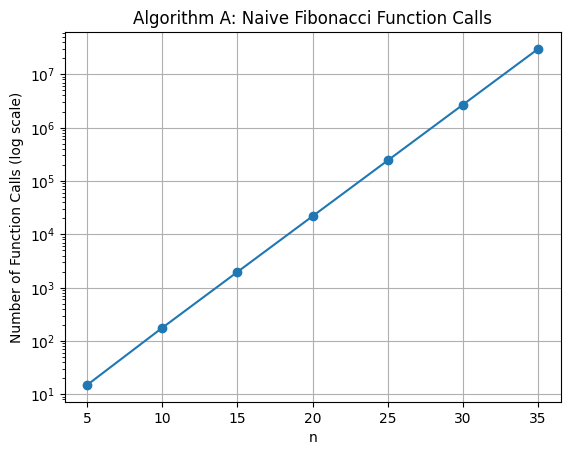

In [24]:
naive_x = [row[0] for row in naive_results]
naive_calls = [row[1] for row in naive_results]

plt.figure()

plt.plot(
    naive_x,
    naive_calls,
    marker="o"
)

plt.yscale("log")

plt.xlabel("n")
plt.ylabel("Number of Function Calls (log scale)")
plt.title("Algorithm A: Naive Fibonacci Function Calls")

plt.grid(True)

plt.show()

## Plot of Function Calls for Algorithm B

The following graph shows the number of calls made by the memoized algorithm.

Unlike Algorithm A, the graph should grow approximately as a straight line because the number of calls grows linearly with \(n\).

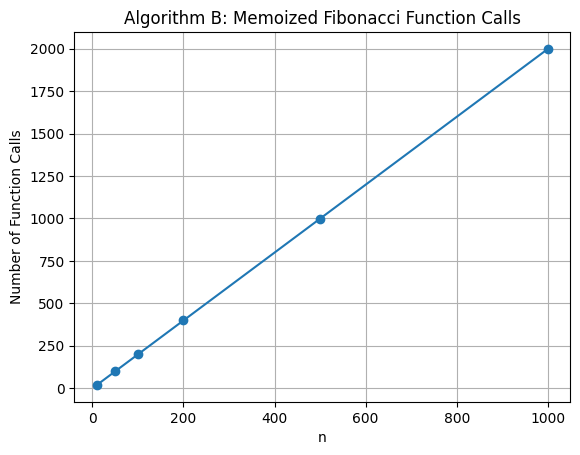

In [25]:
memo_x = [row[0] for row in memo_results]
memo_calls = [row[1] for row in memo_results]

plt.figure()

plt.plot(
    memo_x,
    memo_calls,
    marker="o"
)

plt.xlabel("n")
plt.ylabel("Number of Function Calls")
plt.title("Algorithm B: Memoized Fibonacci Function Calls")

plt.grid(True)

plt.show()

# Part 3: Analysis

The experimental results show that both algorithms compute the same Fibonacci numbers but require very different amounts of work.

This section analyses their function-call recurrences and complexity classes mathematically.

## 3.1 Recurrence for Algorithm A

For $n=0$ or $n=1$, only one function call is required.

Therefore:

$$
C_A(0)=1
$$

$$
C_A(1)=1
$$

For $n \geq 2$, one call is made for the current function and two additional recursive calculations are performed.

Therefore:

$$
C_A(n)=1+C_A(n-1)+C_A(n-2)
$$

The number of calls closely follows the Fibonacci sequence.

## 3.2 Number of Calls Made by Algorithm A

The number of calls made by Algorithm A is:

$$
C_A(n)=2F(n+1)-1
$$

### Base Case

For $n=0$:

$$
2F(1)-1
=
2(1)-1
=
1
$$

which agrees with:

$$
C_A(0)=1
$$

For $n=1$:

$$
2F(2)-1
=
2(1)-1
=
1
$$

which agrees with:

$$
C_A(1)=1
$$

### Inductive Relationship

Using:

$$
C_A(n)=1+C_A(n-1)+C_A(n-2)
$$

and substituting the formula:

$$
C_A(n)
=
1+[2F(n)-1]+[2F(n-1)-1]
$$

Therefore:

$$
C_A(n)=2F(n)+2F(n-1)-1
$$

Since:

$$
F(n+1)=F(n)+F(n-1)
$$

we obtain:

$$
\boxed{C_A(n)=2F(n+1)-1}
$$

## Exponential Growth of Algorithm A

Fibonacci numbers grow approximately according to:

$$
F(n)\approx\frac{\phi^n}{\sqrt{5}}
$$

where:

$$
\phi=\frac{1+\sqrt{5}}{2}\approx1.618
$$

Since the number of calls is:

$$
C_A(n)=2F(n+1)-1
$$

the number of recursive calls grows approximately as:

$$
\Theta(\phi^n)
$$

Therefore, Algorithm A belongs to the **exponential complexity class**.

Its running time can be expressed as:

$$
O(\phi^n)
$$

and is also commonly given using the looser upper bound:

$$
O(2^n)
$$

## 3.3 Recurrence for Algorithm B

Memoization prevents already calculated Fibonacci values from being fully recalculated.

When the memoization table starts empty, calculating $F(n)$ first calculates $F(n-1)$.

After this finishes, the required smaller Fibonacci values have already been stored.

Therefore, the second recursive call becomes a memoization-table lookup.

For $n \geq 2$:

$$
C_B(n)=C_B(n-1)+2
$$

with:

$$
C_B(1)=1
$$

Solving this recurrence gives:

$$
\boxed{C_B(n)=2n-1}
$$

Therefore, the number of function calls grows directly in proportion to $n$.

## Complexity of Algorithm B

Because the memoized algorithm solves each Fibonacci subproblem only once, its running time grows linearly.

Therefore:

$$
\boxed{T(n)=O(n)}
$$

The memoization dictionary stores Fibonacci values from approximately 0 to $n$, requiring:

$$
\boxed{O(n)}
$$

additional memory.

The recursive call stack can also grow to a depth proportional to $n$.

Therefore:

- **Time complexity:** $O(n)$
- **Space complexity:** $O(n)$
- **Complexity class:** Linear

## 3.4 Complexity-Class Comparison

Algorithm A belongs to the **exponential** complexity class because its recursive tree repeatedly recalculates the same subproblems.

Algorithm B belongs to the **linear** complexity class because memoization ensures that each distinct Fibonacci subproblem only needs to be fully calculated once.

The experimental results support the theoretical analysis.

As $n$ increases, Algorithm A's number of calls increases extremely quickly, while Algorithm B's number of calls increases approximately in direct proportion to $n$.

## 3.5 Estimating Algorithm A for n = 1000

From the experiment at $n=35$:

$$
29,860,703
$$

function calls took approximately:

$$
7.4846599\text{ seconds}
$$

Therefore, the measured call rate is approximately:

$$
\frac{29,860,703}{7.4846599}
\approx 3.99 \times 10^6
$$

calls per second.

For Algorithm A:

$$
C_A(1000)=2F(1001)-1
$$

which is approximately:

$$
1.4066 \times 10^{209}
$$

function calls.

Using the measured call rate:

$$
\text{Estimated time}
=
\frac{1.4066 \times 10^{209}}
{3.99 \times 10^6}
$$

$$
\approx 3.53 \times 10^{202}\text{ seconds}
$$

which is approximately:

$$
1.12 \times 10^{195}\text{ years}
$$

# Part 4: Pushing Algorithm B to n = 1000

Although memoization greatly improves the time complexity, Algorithm B still uses recursion.

Python limits the maximum depth of nested recursive calls.

The current recursion limit can be inspected using:

```python
sys.getrecursionlimit()
```

In [26]:


print(
    "Python recursion limit:",
    sys.getrecursionlimit()
)

Python recursion limit: 5000


In [27]:
calls_b = 0
fibtable.clear()

try:
    start = time.perf_counter()

    result_1000_default = fib_memo(1000)

    end = time.perf_counter()

    print("F(1000) =", result_1000_default)
    print("Calls =", calls_b)
    print("Time =", end - start, "seconds")

except RecursionError as e:
    end = time.perf_counter()

    print("RecursionError:", e)
    print("Calls before failure =", calls_b)
    print("Time before failure =", end - start, "seconds")

F(1000) = 43466557686937456435688527675040625802564660517371780402481729089536555417949051890403879840079255169295922593080322634775209689623239873322471161642996440906533187938298969649928516003704476137795166849228875
Calls = 1999
Time = 0.0020508000161498785 seconds


## 4.1 Running Algorithm B at n = 1000

The memoized Fibonacci algorithm still uses recursion.

Before testing $F(1000)$, I checked Python's current recursion limit using:

```python
sys.getrecursionlimit()
```

In my Jupyter environment, `sys.getrecursionlimit()` returned **3000**.

The memoized algorithm successfully calculated $F(1000)$, making **1,999 function calls**.

Therefore, no `RecursionError` occurred in this environment because the recursion limit was high enough for the required recursive call depth.

This shows that the result depends on the recursion limit of the Python environment.

Memoization removes repeated computation, but it does not remove the recursive call stack.


## 4.2 Fix One: Increase the Recursion Limit

One solution is to increase Python's recursion limit using `sys.setrecursionlimit()`.

This allows the original recursive memoized algorithm to continue being used.

### Advantage

The original recursive structure of the algorithm is preserved.

### Disadvantage

A very high recursion limit can consume additional stack memory and may eventually cause instability for extremely deep recursion.

In [28]:
sys.setrecursionlimit(5000)

calls_b = 0
fibtable.clear()

start = time.perf_counter()

result_1000 = fib_memo(1000)

end = time.perf_counter()

print("F(1000) =", result_1000)
print("Calls =", calls_b)
print("Time =", end - start, "seconds")

F(1000) = 43466557686937456435688527675040625802564660517371780402481729089536555417949051890403879840079255169295922593080322634775209689623239873322471161642996440906533187938298969649928516003704476137795166849228875
Calls = 1999
Time = 0.005248699977528304 seconds


## 4.3 Fix Two: Bottom-Up Iterative Fibonacci

A second solution is to remove recursion completely.

Instead of starting from $F(n)$ and recursively moving downward, the algorithm starts from the base cases and builds the solution upward.

This approach is called **bottom-up dynamic programming**.

### Advantages

- No recursion-depth problem.
- Only a loop is required.
- Very little extra memory is necessary.
- Running time remains linear.

### Disadvantage

The implementation no longer follows the recursive structure given in Algorithm B.

In [29]:
def fib_iterative(n):
    
    if n == 0:
        return 0
    
    previous = 0
    current = 1
    
    for i in range(2, n + 1):
        previous, current = (
            current,
            previous + current
        )
    
    return current


start = time.perf_counter()

iterative_result = fib_iterative(1000)

end = time.perf_counter()

print("F(1000) =", iterative_result)
print("Time =", end - start, "seconds")

F(1000) = 43466557686937456435688527675040625802564660517371780402481729089536555417949051890403879840079255169295922593080322634775209689623239873322471161642996440906533187938298969649928516003704476137795166849228875
Time = 0.0005077000241726637 seconds


## 4.4 Problem with the Check `if fibtable[n]`

The original pseudocode suggests checking whether a stored value exists using:

```python
if fibtable[n]:
```

The following test demonstrates the problem when the stored Fibonacci value is zero.

In [30]:

test_table = {0: 0}

print("Stored value:", test_table[0])
print("Boolean test:", bool(test_table[0]))
print("Key exists:", 0 in test_table)

Stored value: 0
Boolean test: False
Key exists: True


The problem occurs for $n=0$, because:

$$
F(0)=0
$$

Even when:

```python
fibtable[0] = 0
```

the condition:

```python
if fibtable[0]:
```

evaluates to `False` because Python treats the integer `0` as a false Boolean value.

Therefore, the program may behave as though $F(0)$ has not already been stored, even though the key `0` exists in the dictionary.

This does not affect the correctness of the final Fibonacci result because $F(0)$ is simply calculated again as 0.

It also does not change the overall time complexity of the memoized algorithm, which remains:

$$
O(n)
$$

However, it causes a small amount of unnecessary repeated work.

A safer implementation is:

```python
if n in fibtable:
    return fibtable[n]
```

This checks whether the key `n` exists in the dictionary instead of checking the Boolean value of the stored Fibonacci number.

# Part 5: Conclusion

The experiments clearly show that the memoized Fibonacci algorithm is far more efficient than the naive recursive algorithm as $n$ increases.

Algorithm A repeatedly solves the same Fibonacci subproblems. Its number of calls follows:

$$
C_A(n)=2F(n+1)-1
$$

which grows exponentially, approximately as $O(\phi^n)$. In our experiment, $n=35$ already required **29,860,703 function calls** and approximately **7.41 seconds**.

Algorithm B avoids most of this repeated work by storing previously calculated Fibonacci values in a memoization table. Its number of calls follows:

$$
C_B(n)=2n-1
$$

giving linear time complexity $O(n)$. For $n=1000$, Algorithm B required only **1,999 calls** and completed in approximately **0.00143 seconds** in our experiment.

By comparison, Algorithm A would require approximately $1.4066 \times 10^{209}$ calls for $n=1000$. At our measured call rate, this would take roughly $1.11 \times 10^{195}$ years, making it completely infeasible.

The key reason memoization works is **overlapping subproblems**. The naive algorithm calculates the same smaller Fibonacci values repeatedly. Memoization stores each result after it is first computed and reuses it whenever that subproblem appears again.

Therefore, as $n$ approaches 1000, Algorithm B is overwhelmingly more practical and efficient than Algorithm A.